# 02 — Análise Exploratória de Dados (EDA) do dataset Beans
**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Este notebook cobre a segunda etapa do projeto: a análise visual e estatística das três classes (`angular_leaf_spot`, `bean_rust` e `healthy`), com o objetivo de embasar as decisões de pré-processamento, data augmentation e modelagem das próximas etapas.

Ele parte do carregamento definido no notebook `01_data_ingestion_preprocessing`, para que todas as análises usem exatamente os mesmos dados do restante do grupo.

## 1. Objetivo da análise
A EDA busca responder quatro perguntas que impactam diretamente a modelagem:

1. As classes estão balanceadas entre treino, validação e teste?
2. As imagens têm propriedades homogêneas (resolução, brilho, contraste)?
3. Existe diferença de cor entre folhas saudáveis e doentes que um modelo possa explorar?
4. Há duplicatas ou vazamento de dados entre os splits, que inflariam as métricas?

## 2. Configuração do ambiente
Importamos as bibliotecas e as funções do pacote `bean_leaf_disease`, e fixamos a semente global (`SEED = 42`) para garantir reprodutibilidade. As figuras geradas são salvas em `reports/figures/` para uso no relatório.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bean_leaf_disease.data.beans import class_distribution, class_names, load_beans_dataset
from bean_leaf_disease.utils.reproducibility import set_global_seed

SEED = 42
set_global_seed(SEED)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

C:\AneHoffmann\MBA_Engenharia_de_Dados\Deep_Learning\bean-leaf-disease-challenge\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Ingestão do dataset
Carregamos o dataset `beans` (AI-Lab Makerere, via Hugging Face) com a função definida na etapa 1. Ele já vem dividido em treino, validação e teste, e cada exemplo contém a imagem e um rótulo entre três classes.

In [2]:
dataset = load_beans_dataset()
labels = class_names(dataset)

print(dataset)
print("Classes:", labels)

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


## 4. Distribuição das classes por split
A distribuição já foi calculada na etapa 1; aqui reproduzimos o gráfico e o salvamos em `reports/figures/` para uso no relatório. Um desbalanceamento forte tornaria a acurácia uma métrica enganosa e exigiria cuidados como pesos de classe ou reamostragem.

**Observações:**
- As três classes estão praticamente equilibradas em todos os splits: treino com 345, 348 e 341 imagens, validação com 44, 45 e 44, e teste com 43, 43 e 42. Cada classe representa cerca de 33% de cada split.
- A divisão é de aproximadamente 80% / 10% / 10% (1034, 133 e 128 imagens).
- Não há necessidade de pesos de classe nem de reamostragem, e a acurácia global não é enganosa neste caso. Ainda assim, o F1-macro e a matriz de confusão mostram em que classes o modelo erra.
- Validação e teste são pequenos (cerca de 130 imagens cada), então cada imagem pesa cerca de 0,75 ponto percentual na acurácia. Pequenas diferenças entre modelos podem ser ruído, e isso deve ser dito na análise de resultados.

,split,label_id,class_name,count,proportion
0,train,0,angular_leaf_spot,345,0.333656
1,train,1,bean_rust,348,0.336557
2,train,2,healthy,341,0.329787
3,validation,0,angular_leaf_spot,44,0.330827
4,validation,1,bean_rust,45,0.338346
5,validation,2,healthy,44,0.330827
6,test,0,angular_leaf_spot,43,0.335938
7,test,1,bean_rust,43,0.335938
8,test,2,healthy,42,0.328125


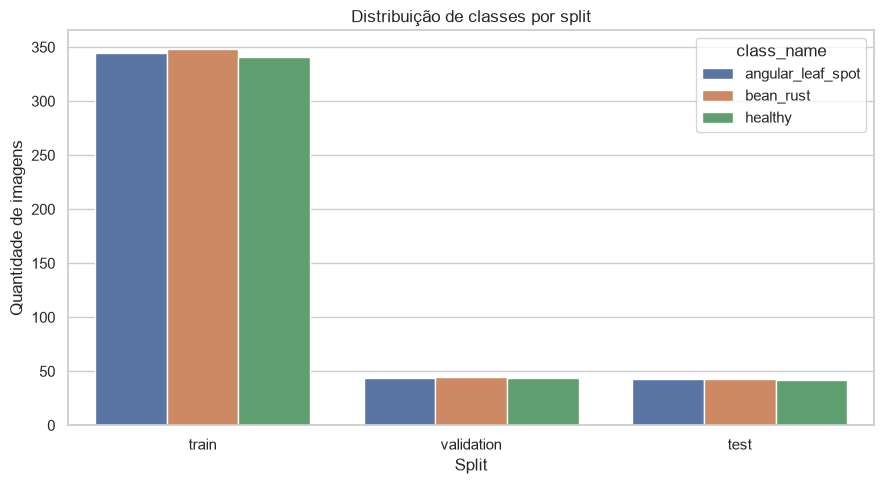

In [3]:
distribution = class_distribution(dataset)
display(distribution)

plt.figure(figsize=(9, 5))
sns.barplot(data=distribution, x="split", y="count", hue="class_name")
plt.title("Distribuição de classes por split")
plt.xlabel("Split"); plt.ylabel("Quantidade de imagens")
plt.tight_layout()
plt.savefig(FIG_DIR / "distribuicao_classes.png", dpi=150)
plt.show()

## 5. Inspeção visual das amostras
A grade mostra quatro exemplos de treino de cada classe. A visualização já existe na etapa 1; aqui ela é salva em `reports/figures/` para o relatório.

**Observações** (com base nos quatro primeiros exemplos de treino de cada classe):
- São fotografias de campo, não imagens de laboratório: o fundo é solo avermelhado, mato e outras folhas, e em vários casos há uma mão segurando a folha. A folha aparece em enquadramentos, escalas e orientações bem diferentes, e a iluminação varia (sol direto, sombra projetada, tons mais escuros).
- `healthy` tem folhas de verde uniforme, sem manchas.
- `angular_leaf_spot` apresenta lesões bem visíveis, marrom-avermelhadas ou escuras, espalhadas pela folha e, em vários exemplos, cercadas por um halo amarelado.
- `bean_rust` apresenta, nestes exemplos, sinais mais discretos: pontos pequenos amarelos ou marrons, esparsos, sobre folhas predominantemente verdes. Pode ser mais difícil de distinguir de `healthy` do que `angular_leaf_spot`.
- As lesões ocupam uma área pequena da imagem, e a redução para 224 × 224 pode apagar parte desse detalhe, principalmente em `bean_rust`.
- Folhas saudáveis às vezes aparecem ao lado de folhas amareladas ou manchadas ao fundo, o que pode confundir o modelo.
- Mãos, unhas pintadas e o tom do solo variam entre as fotos e não estão ligados à doença. O modelo pode aprender esses elementos como atalho, e a augmentation (rotação, flip, brilho e contraste) ajuda a reduzir essa dependência. O Grad-CAM da etapa 4 permite verificar isso.

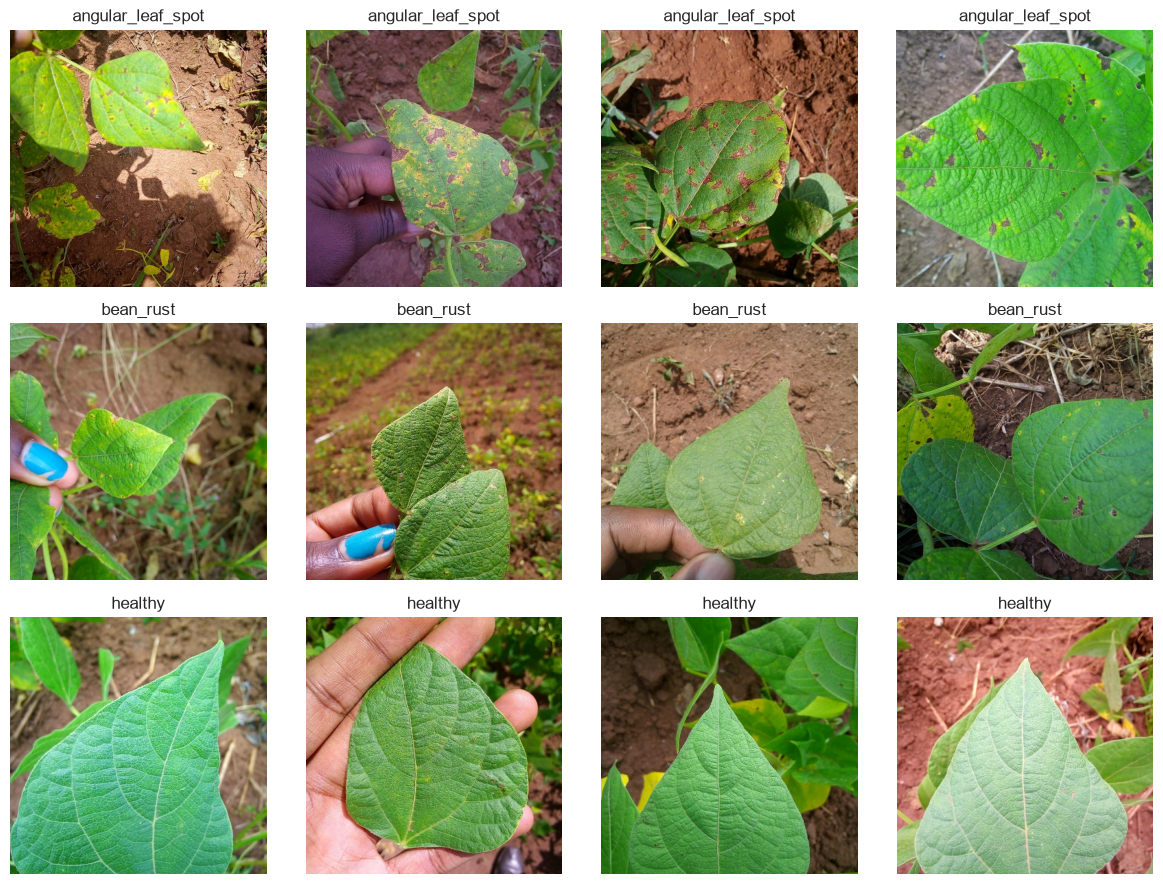

In [4]:
train_labels = np.array(dataset["train"]["labels"])

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for row, class_id in enumerate(range(len(labels))):
    idxs = np.where(train_labels == class_id)[0][:4]
    for col, idx in enumerate(idxs):
        axes[row, col].imshow(dataset["train"][int(idx)]["image"])
        axes[row, col].set_title(labels[class_id])
        axes[row, col].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "amostras_por_classe.png", dpi=150)
plt.show()

## 6. Propriedades das imagens
Calculamos, para todas as imagens dos três splits, a resolução original, a média dos canais R, G e B, o brilho (média em tons de cinza) e o contraste (desvio padrão em tons de cinza). Esses valores alimentam as análises seguintes e justificam o redimensionamento adotado na etapa 1 (224 × 224).

**Observações:**
- Todas as imagens têm a mesma resolução original, 500 × 500 pixels. Por serem quadradas, o redimensionamento para 224 × 224 não distorce a proporção da imagem.
- O brilho médio varia pouco entre as classes (de 0,42 a 0,46), mas o desvio padrão de cerca de 0,08 dentro de cada classe indica variação de iluminação entre as fotos.
- Os valores calculados aqui servem de referência para conferir a normalização usada no pipeline da etapa 1.

In [5]:
def img_stats(img):
    a = np.asarray(img.convert("RGB"), dtype=np.float32) / 255
    g = a.mean(axis=2)
    return dict(w=img.width, h=img.height,
                R=a[..., 0].mean(), G=a[..., 1].mean(), B=a[..., 2].mean(),
                brilho=g.mean(), contraste=g.std())

rows = []
for split in dataset:
    for ex in dataset[split]:
        d = img_stats(ex["image"])
        d["split"] = split
        d["classe"] = labels[ex["labels"]]
        rows.append(d)
stats = pd.DataFrame(rows)

print(stats[["w", "h"]].drop_duplicates())
display(stats.groupby("classe")[["R", "G", "B", "brilho", "contraste"]].agg(["mean", "std"]).round(3))

     w    h
0  500  500


R             G             B        brilho         \
                    mean    std   mean    std   mean    std   mean    std   
classe                                                                      
angular_leaf_spot  0.504  0.101  0.527  0.086  0.286  0.095  0.439  0.078   
bean_rust          0.475  0.107  0.471  0.082  0.307  0.106  0.418  0.088   
healthy            0.476  0.085  0.559  0.085  0.340  0.100  0.458  0.075   

                  contraste         
                       mean    std  
classe                              
angular_leaf_spot     0.158  0.037  
bean_rust             0.168  0.036  
healthy               0.175  0.031

## 7. Brilho e contraste por classe
A variação de iluminação entre fotos de campo é um dos principais desafios do problema. Se brilho e contraste variam bastante dentro de cada classe, o modelo precisa ser robusto a isso, o que justifica augmentation de brilho e contraste.

**Observações:**
- **Brilho:** as medianas são próximas entre as classes (cerca de 0,43 a 0,46), com `healthy` ligeiramente mais clara. Dentro de cada classe, porém, a variação é grande: os valores vão de aproximadamente 0,2 a 0,7, ou seja, há fotos bem escuras e fotos bem claras em todas as classes.
- **Contraste:** as medianas ficam entre cerca de 0,15 e 0,18, com `angular_leaf_spot` mais baixa e `healthy` mais alta. Os intervalos se sobrepõem bastante, e a faixa total vai de cerca de 0,08 a 0,28.
- **Outliers:** são poucos. Aparecem alguns pontos isolados de contraste alto em `bean_rust` (cerca de 0,28) e um em `healthy`, e um ponto de brilho baixo em `angular_leaf_spot`.
- A variação dentro de cada classe é maior do que a diferença entre elas. Isso indica que brilho e contraste refletem principalmente as condições de captura (sol, sombra, câmera), e não a doença, e justifica augmentation de brilho e contraste.

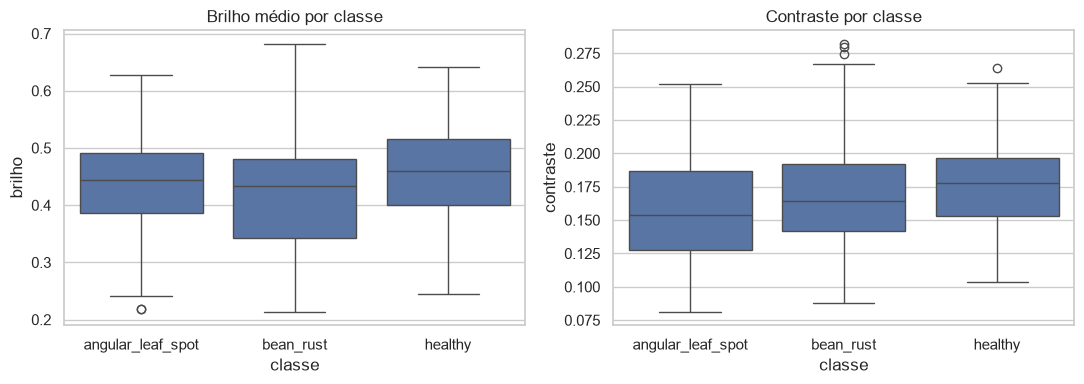

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=stats, x="classe", y="brilho", ax=ax[0]); ax[0].set_title("Brilho médio por classe")
sns.boxplot(data=stats, x="classe", y="contraste", ax=ax[1]); ax[1].set_title("Contraste por classe")
plt.tight_layout()
plt.savefig(FIG_DIR / "brilho_contraste.png", dpi=150)
plt.show()

## 8. Cor média por classe
As doenças alteram a coloração da folha, então a cor pode ser um sinal discriminativo. Ao mesmo tempo, um modelo que dependa demais da cor pode falhar com mudanças de iluminação ou de câmera, o que reforça a importância da augmentation.

**Observações:**
- `healthy` tem o maior verde (G ≈ 0,56) e o maior azul (B ≈ 0,34) entre as classes.
- `bean_rust` tem o menor verde (G ≈ 0,47), praticamente igual ao vermelho (R ≈ 0,48), o que combina com as manchas marrons e amareladas.
- `angular_leaf_spot` tem o maior vermelho (R ≈ 0,50) e o menor azul (B ≈ 0,29).
- A diferença de G entre `healthy` e `bean_rust` (cerca de 0,09) é da ordem de um desvio padrão (cerca de 0,085). Nos demais canais, as diferenças entre classes são menores que o desvio padrão. A cor média é, portanto, um sinal fraco, e as classes se sobrepõem bastante.
- A média é calculada sobre a imagem inteira, incluindo solo, mãos e outras folhas. Parte da diferença pode vir do fundo e não da folha, e isso só pode ser verificado com técnicas de explicabilidade, como o Grad-CAM da etapa 4.

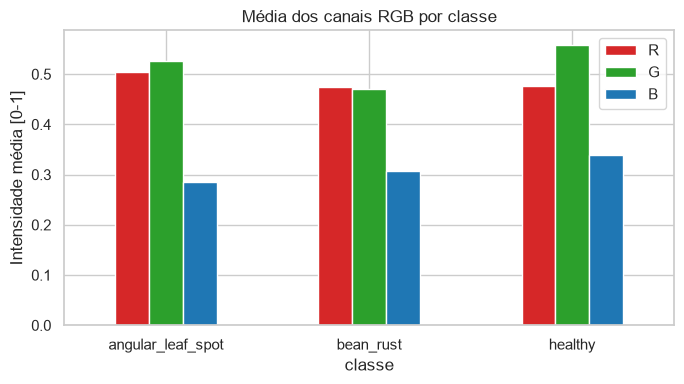

In [7]:
cor = stats.groupby("classe")[["R", "G", "B"]].mean()
cor.plot(kind="bar", color=["#d62728", "#2ca02c", "#1f77b4"], figsize=(7, 4))
plt.title("Média dos canais RGB por classe")
plt.ylabel("Intensidade média [0-1]")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "cor_media_classe.png", dpi=150)
plt.show()

## 9. Duplicatas e vazamento entre splits
Imagens idênticas em treino e teste fazem o modelo ser avaliado em dados que ele já viu, inflando as métricas. Comparamos o hash MD5 de cada imagem dentro de cada split e entre os splits. O método detecta apenas cópias exatas, não imagens parecidas.

**Resultado:**
- Nenhuma duplicata interna em treino (1034 imagens), validação (133) ou teste (128).
- Nenhuma imagem em comum entre treino e validação, treino e teste, ou validação e teste.

**Conclusão:** os três splits são independentes quanto a cópias exatas, e as métricas de validação e teste não são inflacionadas por imagens repetidas. A checagem não cobre fotos diferentes da mesma planta ou da mesma folha, que podem existir em uma base coletada em campo. Isso é uma limitação conhecida, e o dataset não traz informação para verificá-la.

In [8]:
def md5(img):
    return hashlib.md5(img.tobytes()).hexdigest()

hashes = {s: [md5(ex["image"]) for ex in dataset[s]] for s in dataset}

for s, h in hashes.items():
    print(f"{s}: {len(h)} imagens, {len(h) - len(set(h))} duplicatas internas")

print("treino ∩ validação:", len(set(hashes["train"]) & set(hashes["validation"])))
print("treino ∩ teste:", len(set(hashes["train"]) & set(hashes["test"])))
print("validação ∩ teste:", len(set(hashes["validation"]) & set(hashes["test"])))

train: 1034 imagens, 0 duplicatas internas
validation: 133 imagens, 0 duplicatas internas
test: 128 imagens, 0 duplicatas internas
treino ∩ validação: 0
treino ∩ teste: 0
validação ∩ teste: 0


## 10. Implicações para data augmentation e modelagem

| Achado da EDA | Decisão proposta |
|---|---|
| Brilho e contraste variam muito dentro de cada classe (brilho de cerca de 0,2 a 0,7) | Augmentation de brilho e contraste |
| Fotos de campo, com folhas em enquadramentos, escalas e orientações diferentes | Rotação, flip horizontal e, se o grupo quiser testar, zoom ou recorte aleatório |
| Classes equilibradas (cerca de 33% cada) | Sem pesos de classe nem reamostragem; reportar acurácia global, F1-macro e matriz de confusão |
| Validação e teste pequenos (133 e 128 imagens) | Tratar diferenças pequenas entre modelos com cautela, pois cada imagem vale cerca de 0,75 ponto percentual |
| Cor média separa pouco as classes e o fundo (solo, mãos) varia | Usar augmentation para reduzir dependência do fundo e verificar com Grad-CAM na etapa 4 |
| Nenhum vazamento entre splits | Manter os splits originais do dataset |

Ponto a discutir: as imagens originais têm 500 × 500 pixels e as lesões ocupam uma área pequena. O redimensionamento para 224 × 224 reduz o detalhe das manchas, e vale testar uma resolução maior se o baseline tiver dificuldade com as classes doentes.

## 11. Conclusões e próximos passos
**Principais achados:**
- O dataset é bem equilibrado: 1034, 133 e 128 imagens, com cerca de 33% de cada classe em cada split.
- Todas as imagens têm 500 × 500 pixels, e a iluminação varia bastante dentro de cada classe.
- A cor média difere entre as classes, mas de forma modesta em relação à variação interna, então não deve ser suficiente por si só.
- Não há duplicatas internas nem vazamento entre treino, validação e teste.

**Próximos passos:** treinar o baseline com o pipeline da etapa 1 e aplicar a augmentation da seção 10, avaliar com as métricas do desafio e, na etapa 4, usar Grad-CAM para verificar se o modelo olha para a folha ou para o fundo.

In [9]:
out_dir = Path("../data/processed")
out_dir.mkdir(parents=True, exist_ok=True)
stats.to_csv(out_dir / "image_stats.csv", index=False)
print("Estatísticas salvas em data/processed/image_stats.csv")

Estatísticas salvas em data/processed/image_stats.csv
